# 00. データ検証

analysis_panel.csv の整合性チェックと分析設計の確定。

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import japanize_matplotlib

df = pd.read_csv('../data/analysis_panel.csv')
print(f'Shape: {df.shape}')
print(f'Columns: {list(df.columns)}')

## 1. 行数・構造チェック

In [2]:
n_prefs = df['pref_code'].nunique()
year_months = df.groupby(['year', 'month']).ngroups
print(f'都道府県数: {n_prefs}')
print(f'年月数: {year_months}')
print(f'期待行数: {n_prefs} × {year_months} = {n_prefs * year_months}')
print(f'実際行数: {len(df)}')
assert len(df) == n_prefs * year_months, '行数不一致！'

# 年別月数
ym = df.groupby('year')['month'].nunique()
print('\n年別月数:')
print(ym.to_string())
print(f'\n2019年は {ym[2019]} ヶ月のみ（5-12月欠測）')

都道府県数: 47
年月数: 151
期待行数: 47 × 151 = 7097
実際行数: 7097

年別月数:
year
2013    12
2014    12
2015    12
2016    12
2017    12
2018    12
2019     4
2020    12
2021    12
2022    12
2023    12
2024    12
2025    12
2026     3

2019年は 4 ヶ月のみ（5-12月欠測）


In [3]:
# pref_code と pref_name の 1:1 対応
pref_map = df.groupby('pref_code')['pref_name'].nunique()
assert (pref_map == 1).all(), 'pref_code と pref_name が 1:1 でない'

pref_list = df[['pref_code', 'pref_name']].drop_duplicates().sort_values('pref_code')
print(f'都道府県一覧 ({len(pref_list)}):')
for _, r in pref_list.iterrows():
    print(f'  {r["pref_code"]:2d} {r["pref_name"]}')

都道府県一覧 (47):
   1 北海道
   2 青森
   3 岩手
   4 宮城
   5 秋田
   6 山形
   7 福島
   8 茨城
   9 栃木
  10 群馬
  11 埼玉
  12 千葉
  13 東京
  14 神奈川
  15 新潟
  16 富山
  17 石川
  18 福井
  19 山梨
  20 長野
  21 岐阜
  22 静岡
  23 愛知
  24 三重
  25 滋賀
  26 京都
  27 大阪
  28 兵庫
  29 奈良
  30 和歌山
  31 鳥取
  32 島根
  33 岡山
  34 広島
  35 山口
  36 徳島
  37 香川
  38 愛媛
  39 高知
  40 福岡
  41 佐賀
  42 長崎
  43 熊本
  44 大分
  45 宮崎
  46 鹿児島
  47 沖縄


## 2. MW改定タイミングの検証

In [4]:
# 9月→10月の切り替わりを spot check
def check_mw_transition(pref_name):
    sub = df[df['pref_name'] == pref_name].sort_values(['year', 'month'])
    sub = sub[sub['month'].isin([9, 10, 11])]
    sub['mw_changed'] = sub['min_wage'] != sub['min_wage'].shift(1)
    changes = sub[sub['mw_changed'] & (sub['month'] == 10)]
    print(f'\n{pref_name}: MW変更は10月に {len(changes)} 回')
    # 10月以外の変更
    non_oct = sub[sub['mw_changed'] & (sub['month'] != 10)]
    if len(non_oct) > 0:
        print(f'  ⚠ 10月以外の変更: {len(non_oct)} 回')
    return sub[['year', 'month', 'min_wage']].head(18)

for p in ['東京', '沖縄', '大阪', '北海道']:
    print(check_mw_transition(p).to_string(index=False))


東京: MW変更は10月に 11 回
  ⚠ 10月以外の変更: 2 回
 year  month  min_wage
 2013      9     850.0
 2013     10     869.0
 2013     11     869.0
 2014      9     869.0
 2014     10     888.0
 2014     11     888.0
 2015      9     888.0
 2015     10     907.0
 2015     11     907.0
 2016      9     907.0
 2016     10     932.0
 2016     11     932.0
 2017      9     932.0
 2017     10     958.0
 2017     11     958.0
 2018      9     958.0
 2018     10     985.0
 2018     11     985.0

沖縄: MW変更は10月に 11 回
  ⚠ 10月以外の変更: 2 回
 year  month  min_wage
 2013      9     653.0
 2013     10     664.0
 2013     11     664.0
 2014      9     664.0
 2014     10     677.0
 2014     11     677.0
 2015      9     677.0
 2015     10     693.0
 2015     11     693.0
 2016      9     693.0
 2016     10     714.0
 2016     11     714.0
 2017      9     714.0
 2017     10     737.0
 2017     11     737.0
 2018      9     737.0
 2018     10     762.0
 2018     11     762.0

大阪: MW変更は10月に 10 回
  ⚠ 10月以外の変更: 3 回
 year  month

In [5]:
# 全都道府県でMW変更が起きる月の分布
df_sorted = df.sort_values(['pref_code', 'year', 'month'])
df_sorted['mw_diff'] = df_sorted.groupby('pref_code')['min_wage'].diff()
changes = df_sorted[df_sorted['mw_diff'] > 0]
print('MW上昇が起きた月の分布:')
print(changes['month'].value_counts().sort_index())
print(f'\n10月に集中: {(changes["month"] == 10).mean():.1%}')

MW上昇が起きた月の分布:
month
1      51
3       2
9       1
10    526
11     16
12      8
Name: count, dtype: int64

10月に集中: 87.1%


## 3. アウトカム変数の異常値チェック

In [6]:
outcome_cols = ['wage_total', 'wage_regular', 'wage_scheduled', 'wage_special',
                'wage_overtime', 'hours_total', 'hours_scheduled', 'hours_overtime',
                'days_worked', 'workers']

print('=== 基本統計量 ===')
print(df[outcome_cols].describe().round(1).to_string())

# z-score で外れ値検出
print('\n=== |z| > 4 の外れ値 ===')
for col in outcome_cols:
    z = (df[col] - df[col].mean()) / df[col].std()
    outliers = df[z.abs() > 4]
    if len(outliers) > 0:
        print(f'{col}: {len(outliers)} 件')
        print(outliers[['pref_name', 'year', 'month', col]].head(5).to_string(index=False))
        print()

=== 基本統計量 ===
       wage_total  wage_regular  wage_scheduled  wage_special  wage_overtime  hours_total  hours_scheduled  hours_overtime  days_worked  workers
count      7097.0        7097.0          7097.0        7097.0         7097.0       7097.0           7097.0          7097.0       7097.0   7097.0
mean     296143.4      247618.2        229892.6       48531.4        17725.6        142.6            132.7            10.0         18.6   1000.6
std       86066.9       20788.9         18783.4       80837.6         3056.0          8.3              7.8             1.4          1.0   1291.9
min      203638.0      200747.0        188265.0         218.0         9534.0        109.0            102.9             5.2         14.9     70.2
25%      246596.0      235257.0        218843.0        4829.0        15529.0        137.0            127.4             9.0         17.9    373.0
50%      260897.0      246105.0        228347.0       10563.0        17582.0        142.9            132.9          

hours_overtime: 1 件
pref_name  year  month  hours_overtime
       茨城  2014      4            15.8

workers: 151 件
pref_name  year  month  workers
       東京  2013      1   7150.9
       東京  2013      2   7129.5
       東京  2013      3   7095.5
       東京  2013      4   7170.7
       東京  2013      5   7208.3



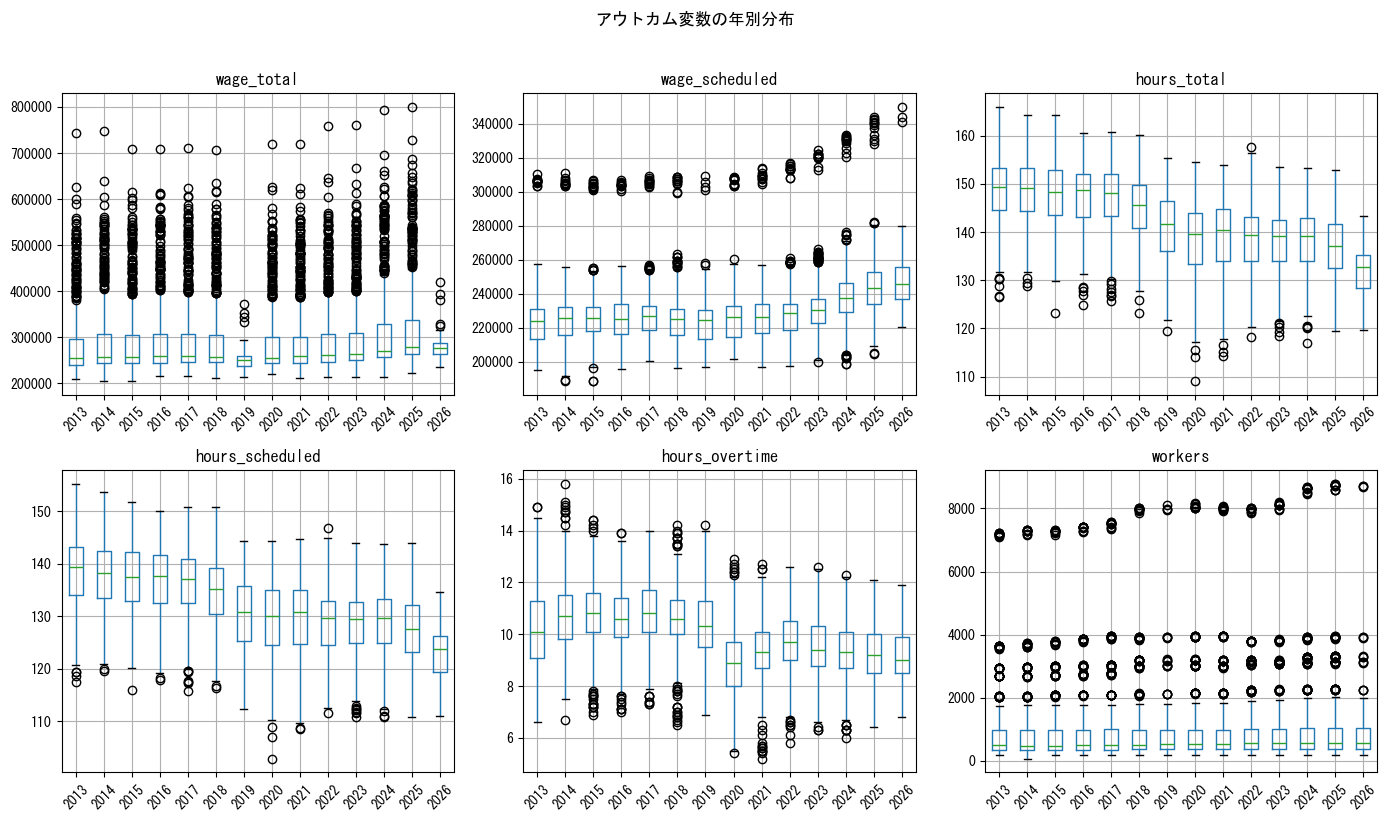

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
plot_cols = ['wage_total', 'wage_scheduled', 'hours_total',
             'hours_scheduled', 'hours_overtime', 'workers']
for ax, col in zip(axes.flat, plot_cols):
    df.boxplot(column=col, by='year', ax=ax, showfliers=True)
    ax.set_title(col)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=45)
plt.suptitle('アウトカム変数の年別分布', y=1.02)
plt.tight_layout()
plt.savefig('../output/figures/00_outlier_boxplots.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. log(MW) の variation 確認

In [8]:
# 全体の変動
print('=== log(MW) の変動 ===')
print(f'Overall std: {df["log_mw"].std():.4f}')

# Within 変動（FE除去後）
df['log_mw_demean_pref'] = df['log_mw'] - df.groupby('pref_code')['log_mw'].transform('mean')
df['ym'] = df['year'] * 100 + df['month']
df['log_mw_within'] = df['log_mw_demean_pref'] - df.groupby('ym')['log_mw_demean_pref'].transform('mean')

print(f'Within (pref+time FE除去後) std: {df["log_mw_within"].std():.6f}')
print(f'\n→ FE除去後のwithin変動は非常に小さい')
print('  これはTWFEの識別変動が限定的であることを示唆')

# 年次の変化幅
oct = df[df['month'] == 10].copy()
oct = oct.sort_values(['pref_code', 'year'])
oct['dlog_mw'] = oct.groupby('pref_code')['log_mw'].diff()
print('\n=== 年次 Δlog(MW)（10月ベース）===')
print(oct.groupby('year')['dlog_mw'].describe()[['mean', 'std', 'min', 'max']].dropna().round(4).to_string())

=== log(MW) の変動 ===
Overall std: 0.1344
Within (pref+time FE除去後) std: 0.008142

→ FE除去後のwithin変動は非常に小さい
  これはTWFEの識別変動が限定的であることを示唆

=== 年次 Δlog(MW)（10月ベース）===
        mean     std     min     max
year                                
2014  0.0216  0.0039  0.0189  0.0406
2015  0.0231  0.0012  0.0201  0.0250
2016  0.0299  0.0010  0.0272  0.0317
2017  0.0308  0.0011  0.0275  0.0330
2018  0.0318  0.0014  0.0278  0.0345
2020  0.0348  0.0034  0.0280  0.0412
2021  0.0331  0.0025  0.0273  0.0396
2022  0.0353  0.0026  0.0293  0.0395
2023  0.0455  0.0043  0.0375  0.0536
2024  0.0530  0.0095  0.0000  0.0640
2025  0.0282  0.0322  0.0000  0.0896


## 5. 2019年ギャップと分析サンプルの決定

In [9]:
# 2019年のデータ
df_2019 = df[df['year'] == 2019]
print(f'2019年: {len(df_2019)} 行, 月: {sorted(df_2019["month"].unique())}')
print(f'→ 1-4月のみ。5-12月は欠測。')
print(f'→ 2019年10月のMW改定は観察できない。')

# 2019年を含めた場合 vs 除外した場合
print('\n=== サンプル候補 ===')
for label, mask in [
    ('全期間', df['year'] >= 2013),
    ('2019除外', (df['year'] >= 2013) & (df['year'] != 2019)),
    ('2013-2018+2020-2025', (df['year'] >= 2013) & (df['year'] != 2019) & (df['year'] <= 2025)),
]:
    sub = df[mask]
    print(f'{label}: {len(sub)} 行, {sub["pref_code"].nunique()} 都道府県, '
          f'{sub.groupby(["year","month"]).ngroups} 年月')

2019年: 188 行, 月: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
→ 1-4月のみ。5-12月は欠測。
→ 2019年10月のMW改定は観察できない。

=== サンプル候補 ===
全期間: 7097 行, 47 都道府県, 151 年月
2019除外: 6909 行, 47 都道府県, 147 年月
2013-2018+2020-2025: 6768 行, 47 都道府県, 144 年月


In [10]:
# 分析サンプルの作成
# 2019年除外、2026年は3月までだが含める
panel = df[(df['year'] != 2019)].copy()
panel = panel.sort_values(['pref_code', 'year', 'month']).reset_index(drop=True)

print(f'分析サンプル: {len(panel)} 行')
print(f'期間: {panel["year"].min()}-{panel["month"].min():02d} 〜 '
      f'{panel["year"].max()}-{panel.loc[panel["year"]==panel["year"].max(), "month"].max():02d}')
print(f'都道府県: {panel["pref_code"].nunique()}')
print(f'年月数: {panel.groupby(["year", "month"]).ngroups}')

# log変換
for col in ['wage_total', 'wage_scheduled', 'hours_total', 'hours_scheduled', 'workers']:
    panel[f'log_{col}'] = np.log(panel[col])

# 保存（分析に必要なカラムのみ）
save_cols = ['pref_code', 'pref_name', 'year', 'month',
             'workers', 'hours_total', 'hours_scheduled', 'hours_overtime', 'days_worked',
             'wage_total', 'wage_regular', 'wage_scheduled', 'wage_special', 'wage_overtime',
             'min_wage', 'log_mw',
             'log_wage_total', 'log_wage_scheduled', 'log_hours_total', 'log_hours_scheduled', 'log_workers']
panel[save_cols].to_csv('../data/analysis_sample.csv', index=False)
print(f'\n→ data/analysis_sample.csv に保存（{len(save_cols)} カラム、2019除外済み）')

分析サンプル: 6909 行
期間: 2013-01 〜 2026-03
都道府県: 47
年月数: 147



→ data/analysis_sample.csv に保存（21 カラム、2019除外済み）


## 6. まとめ

In [11]:
print('=== データ検証まとめ ===')
print()
print('1. 構造: 47都道府県 × 月次パネル、欠損なし')
print('2. 2019年5-12月欠測 → 2019年まるごと除外')
print('3. MW改定は10月に87%集中（残りは端数調整等）')
print('4. log(MW) のwithin変動は非常に小さい')
print('   → TWFEの識別変動が限定的（contdid/dcDH の動機づけ）')
print('5. 全都道府県が毎年MW改定 → no stayer')
print('   → Callaway et al. (2024) contdid ではなく')
print('     De Chaisemartin et al. (2024) の手法が適切か（Phase 3で検討）')
print()
print(f'分析サンプル: data/analysis_sample.csv ({len(panel)} 行)')

=== データ検証まとめ ===

1. 構造: 47都道府県 × 月次パネル、欠損なし
2. 2019年5-12月欠測 → 2019年まるごと除外
3. MW改定は10月に87%集中（残りは端数調整等）
4. log(MW) のwithin変動は非常に小さい
   → TWFEの識別変動が限定的（contdid/dcDH の動機づけ）
5. 全都道府県が毎年MW改定 → no stayer
   → Callaway et al. (2024) contdid ではなく
     De Chaisemartin et al. (2024) の手法が適切か（Phase 3で検討）

分析サンプル: data/analysis_sample.csv (6909 行)
